<a href="https://colab.research.google.com/github/Knault2/DSML-Assignment-5/blob/main/Keira_Nault_Assignment5_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Science Workflow: Grocery Revenue Analysis
**Author:** [Keira Nault] | **Date:** [27/10/2026] | **File:** Keira_Nault_Assignment5_Notebook.ipynb
---
### Research Question
Which features (Price, Sales, Discount, and Product) show the strongest connection to Revenue of groceries, and how can data-driven insights help grocery stores maximize their revenue?

## Step - 1 Data Ingestion: Student Performance
Importing necessary libraries. Loading historical data, retail sales statistics dataset (retail_sales_comma_separated.csv). In Orange this was represented by the File widget and Data Table widget.
Inspecting the raw dataset:

train_df.shape provides dataset size.

train_df.head() shows the first 5 rows, ensuring data is loaded.

This is the regression version of the workflow: Revenue is the numerical outcome to predict.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.feature_selection import mutual_info_regression

# Load historical retail dataset
train_df = pd.read_csv('sample_data/retail_sales_comma_separated.csv')

# Inspect the raw dataset
print("Dataset Shape:", train_df.shape)
display(train_df.head())

Dataset Shape: (1499, 10)


,Province,City,Store,Year,Month,Product,Price,Discount,Sales,Revenue
0,British Columbia,Vancouver,Store 1,2023,1,Bread,4.08,30,141,402.70
1,British Columbia,Vancouver,Store 1,2023,1,Milk,5.67,10,105,535.82
2,British Columbia,Vancouver,Store 1,2023,1,Bread,3.39,40,176,357.98
3,British Columbia,Vancouver,Store 1,2023,2,Bread,3.97,25,153,455.56
4,British Columbia,Vancouver,Store 1,2023,2,Apples,4.46,0,68,303.28


## Step 2 - Feature Engineering and Role Assignment

In Orange, this role assignment corresponds to the **Select Columns** widget.

Set `Revenue` as the numerical target. Keep `Province`, `City`, `Store`, `Year`, `Month`, `Product` as a meta/identifier field, not a model input.

In [ ]:
# Define column roles
target_col = 'Revenue'       # Numerical target for regression
meta_cols = ['Province', 'City', 'Store', 'Year', 'Month', 'Product']       # Identifier; not used for training
excluded_cols = meta_cols + [target_col]

# Use all remaining columns as predictors
feature_cols = [c for c in train_df.columns if c not in excluded_cols]

# Ensure the target is numeric and remove rows without a target
train_df[target_col] = pd.to_numeric(train_df[target_col], errors='coerce')
train_df = train_df.dropna(subset=[target_col]).copy()

X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()

print(f"Features ({len(feature_cols)}):", feature_cols)
print("Target Variable:", target_col)
print("Target data type:", y_train.dtype)

Features (3): ['Price', 'Discount', 'Sales']
Target Variable: Revenue
Target data type: float64


## Step 3 - Inspection: Framed Data
In Orange this was a Data Table widget, now it inspects predictor data types, missing values, and the distribution of the numerical target. Regression predicts a numeric value, so the target should be numeric and the evaluation will use regression metrics rather than classification metrics.

--- Predictor Data Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1499 entries, 0 to 1498
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Price     1499 non-null   float64
 1   Discount  1499 non-null   int64  
 2   Sales     1499 non-null   int64  
dtypes: float64(1), int64(2)
memory usage: 35.3 KB
\n--- Missing Values in Predictors ---


,Missing Values
Price,0
Discount,0
Sales,0


\n--- Revenue Summary ---


,Revenue
count,1499.000000
mean,446.400280
std,126.192441
min,142.850000
25%,359.500000
50%,439.040000
75%,524.505000
max,847.120000


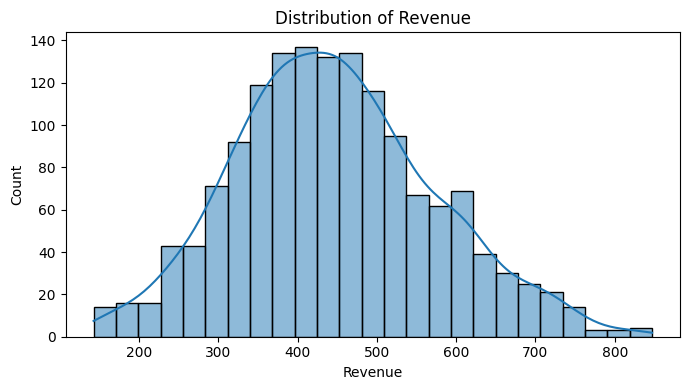

In [ ]:
print("--- Predictor Data Summary ---")
train_df[feature_cols].info()

print("\\n--- Missing Values in Predictors ---")
display(train_df[feature_cols].isna().sum().rename('Missing Values').to_frame())

print("\\n--- Revenue Summary ---")
display(y_train.describe().to_frame())

plt.figure(figsize=(7, 4))
sns.histplot(y_train, kde=True)
plt.title("Distribution of Revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.show()

# Exercise 2: Train and Inspect a Decision Tree Regression Model

## Step 4 - Model: Decision Tree Regression Initialization

In Orange, this corresponds to the **Tree** learner configured for a numerical target. Here, use scikit-learn's `DecisionTreeRegressor`, not `DecisionTreeClassifier`. The model predicts a numeric FinalGrade.

In [ ]:
# Decision Tree Regressor
dt_model = DecisionTreeRegressor(
    criterion='squared_error',
    min_samples_split=5,
    min_samples_leaf=2,
    max_depth=100,
    random_state=42
)

dt_model.fit(X_train, y_train)
print("Decision Tree Regressor trained.")

Decision Tree Regressor trained.


# Step 5 - Inspection: Visual Decision Rules

In Orange, was a Tree Viewer widget.

Inspect the trained regression tree's decision rules. The terminal leaves contain predicted numerical FinalGrade values rather than class labels.

--- Decision Tree Regression Rules ---
|--- Price <= 4.74
|   |--- Discount <= 45.00
|   |   |--- Sales <= 88.50
|   |   |   |--- Sales <= 77.50
|   |   |   |   |--- Sales <= 69.50
|   |   |   |   |   |--- Sales <= 62.50
|   |   |   |   |   |   |--- Price <= 4.30
|   |   |   |   |   |   |   |--- value: [251.22]
|   |   |   |   |   |   |--- Price >  4.30
|   |   |   |   |   |   |   |--- Sales <= 58.50
|   |   |   |   |   |   |   |   |--- value: [264.97]
|   |   |   |   |   |   |   |--- Sales >  58.50
|   |   |   |   |   |   |   |   |--- value: [274.68]
|   |   |   |   |   |--- Sales >  62.50
|   |   |   |   |   |   |--- Price <= 4.65
|   |   |   |   |   |   |   |--- Price <= 4.35
|   |   |   |   |   |   |   |   |--- Sales <= 68.00
|   |   |   |   |   |   |   |   |   |--- value: [274.43]
|   |   |   |   |   |   |   |   |--- Sales >  68.00
|   |   |   |   |   |   |   |   |   |--- Price <= 4.17
|   |   |   |   |   |   |   |   |   |   |--- value: [282.90]
|   |   |   |   |   |   |   |   |  

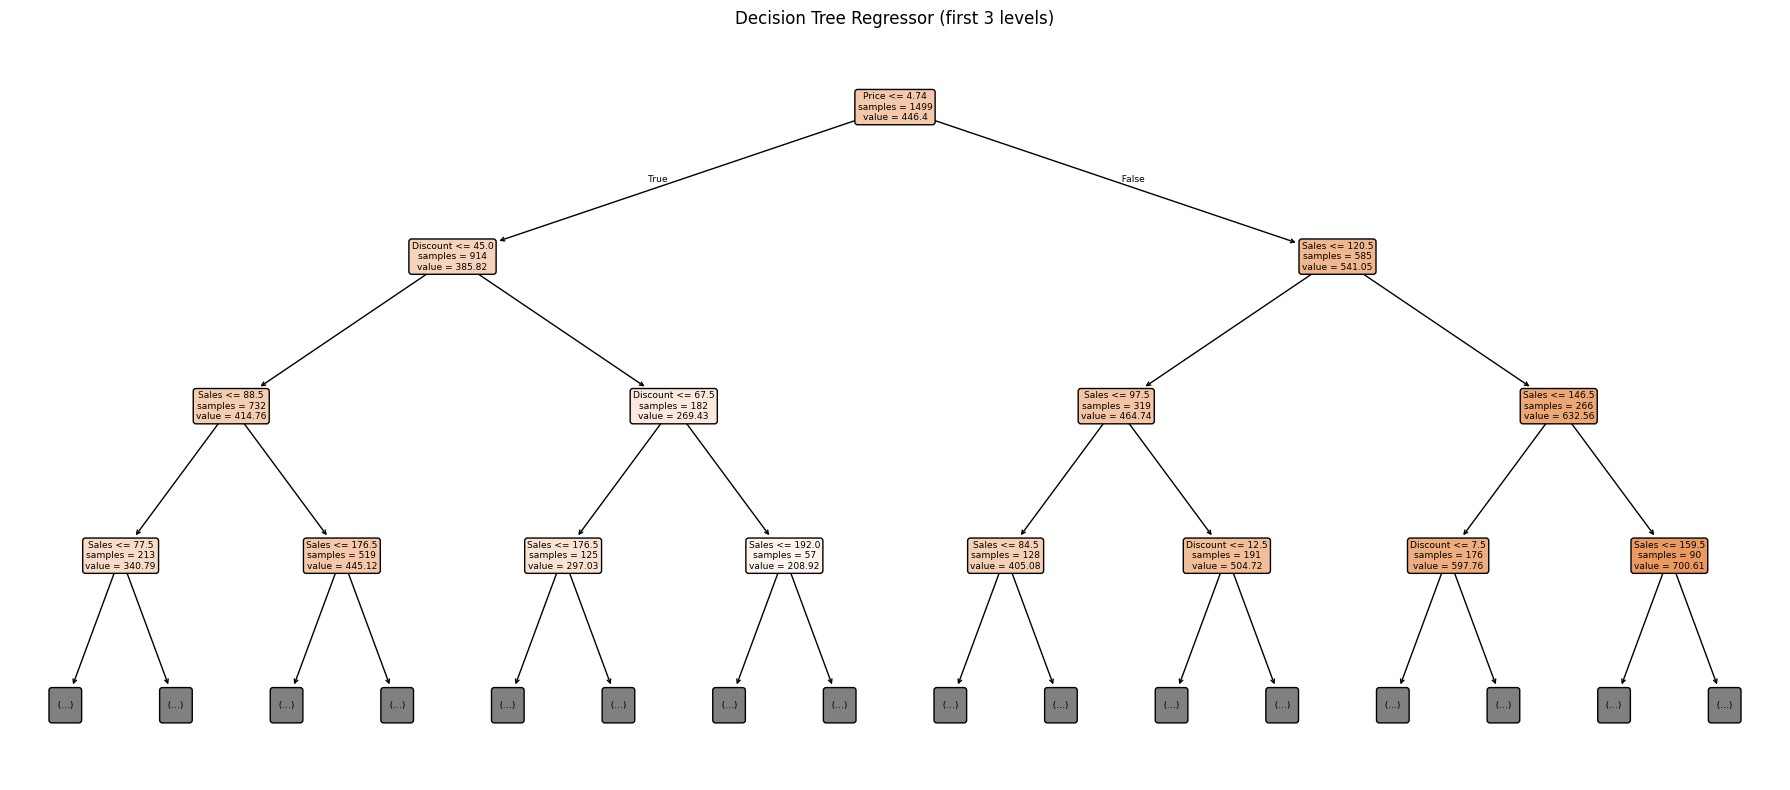

In [ ]:
tree_rules = export_text(dt_model, feature_names=list(feature_cols))
print("--- Decision Tree Regression Rules ---")
print(tree_rules)

# Optional visual overview; limit displayed depth to keep the diagram readable
plt.figure(figsize=(18, 8))
plot_tree(
    dt_model,
    feature_names=list(feature_cols),
    filled=True,
    rounded=True,
    max_depth=3,
    impurity=False,
    precision=2
)
plt.title("Decision Tree Regressor (first 3 levels)")
plt.tight_layout()
plt.show()

# Exercise 3: Evaluate Decision Tree and Random Forest Regression Models

## Step 6 - Model: Random Forest Regression Initialization

Configure a **RandomForestRegressor** to predict numerical Revenue. A random forest averages predictions from multiple decision trees, which can help produce more stable estimates.

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_split=5,
    random_state=42
)

rf_model.fit(X_train, y_train)
print("Random Forest Regressor trained.")

Random Forest Regressor trained.


## Step 7 - Test and Score (Regression Evaluator)

This is the regression equivalent of Orange's **Test & Score** widget. Use shuffled 5-fold cross-validation to compare both models using:

- **R²**: higher is generally better; 1.0 is a perfect fit, and values below 0 can occur.
- **MAE (Mean Absolute Error)**: average absolute prediction error, in FinalGrade units; lower is better.
- **MSE (Mean Squared Error)** and **RMSE (Root Mean Squared Error)**: penalize larger errors more strongly; lower is better.

The scoring API returns negative values for error metrics so that all scorers follow the convention “higher is better”; the table below converts those scores back to positive error values.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Decision Tree Regression": dt_model,
    "Random Forest Regression": rf_model
}

scoring = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error',
    'MSE': 'neg_mean_squared_error',
    'RMSE': 'neg_root_mean_squared_error'
}

results = []
for name, model in models.items():
    cv_results = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results.append({
        'Model': name,
        'R2 (mean)': cv_results['test_R2'].mean(),
        'MAE (mean)': -cv_results['test_MAE'].mean(),
        'MSE (mean)': -cv_results['test_MSE'].mean(),
        'RMSE (mean)': -cv_results['test_RMSE'].mean()
    })

score_board = pd.DataFrame(results).sort_values('R2 (mean)', ascending=False)
display(score_board.round(4))

,Model,R2 (mean),MAE (mean),MSE (mean),RMSE (mean)
0,Decision Tree Regression,0.9750,14.0414,392.2561,19.6713
1,Random Forest Regression,0.8163,40.8872,2905.4414,53.8077


## Step 8 - Inspection: Regression Error Scoreboard

A confusion matrix is designed for classification and is not appropriate for a continuous numerical target. Instead, inspect cross-validated predictions using actual-versus-predicted plots and residuals (actual minus predicted). Residuals near zero indicate smaller errors; patterns may indicate systematic under- or over-prediction.

--- Decision Tree Regression cross-validation errors ---
R2:   0.9754
MAE:  14.0404
MSE:  392.2020
RMSE: 19.8041
--- Random Forest Regression cross-validation errors ---
R2:   0.8174
MAE:  40.8865
MSE:  2905.2876
RMSE: 53.9007


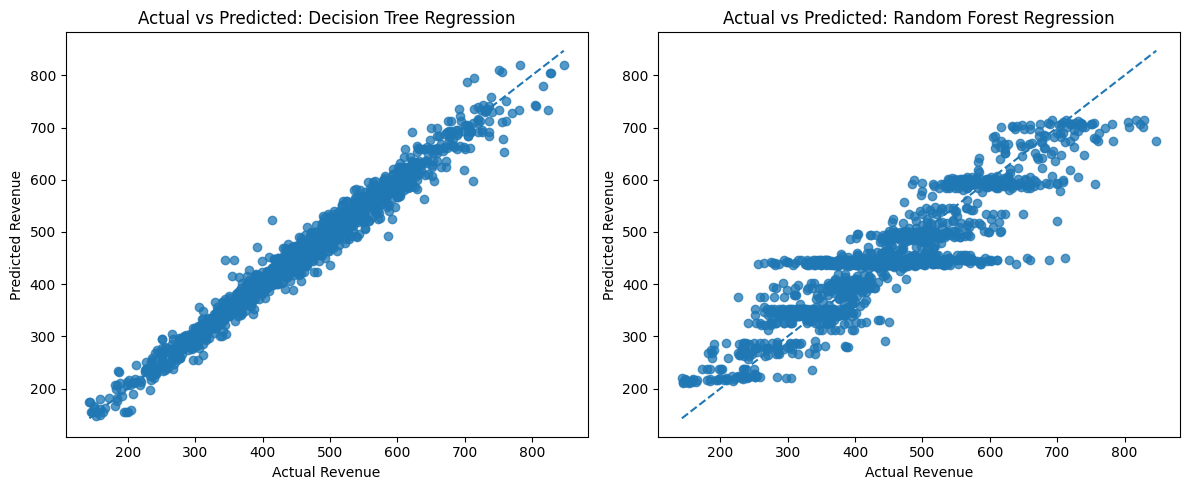

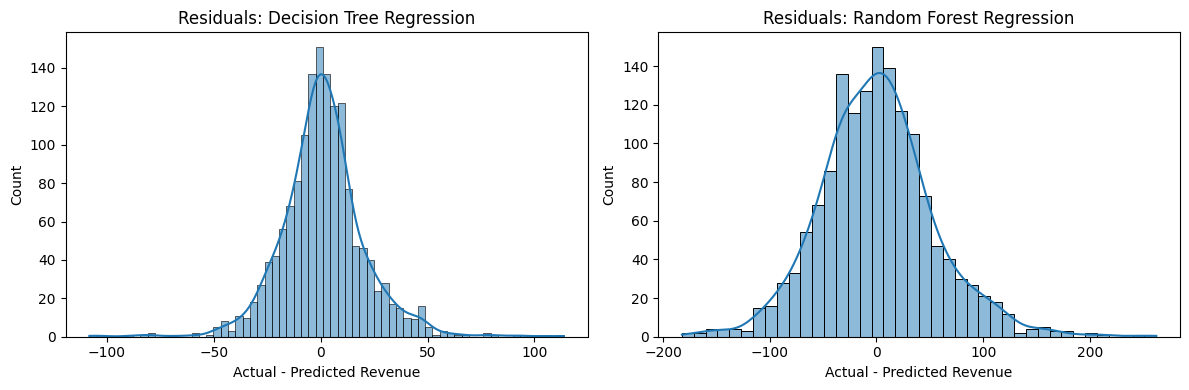

In [ ]:
# Generate out-of-fold predictions so each row is predicted by a model
# that did not train on that row's fold.
cv_predictions = {}
for name, model in models.items():
    y_pred_cv = cross_val_predict(model, X_train, y_train, cv=cv)
    cv_predictions[name] = y_pred_cv

    residuals = y_train.to_numpy() - y_pred_cv
    print(f"--- {name} cross-validation errors ---")
    print(f"R2:   {r2_score(y_train, y_pred_cv):.4f}")
    print(f"MAE:  {mean_absolute_error(y_train, y_pred_cv):.4f}")
    print(f"MSE:  {mean_squared_error(y_train, y_pred_cv):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_cv)):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred_cv) in zip(axes, cv_predictions.items()):
    residuals = y_train.to_numpy() - y_pred_cv
    ax.scatter(y_train, y_pred_cv, alpha=0.75)
    min_val = min(y_train.min(), np.min(y_pred_cv))
    max_val = max(y_train.max(), np.max(y_pred_cv))
    ax.plot([min_val, max_val], [min_val, max_val], linestyle='--')
    ax.set_title(f"Actual vs Predicted: {name}")
    ax.set_xlabel("Actual Revenue")
    ax.set_ylabel("Predicted Revenue")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, y_pred_cv) in zip(axes, cv_predictions.items()):
    residuals = y_train.to_numpy() - y_pred_cv
    sns.histplot(residuals, kde=True, ax=ax)
    ax.set_title(f"Residuals: {name}")
    ax.set_xlabel("Actual - Predicted Revenue")
plt.tight_layout()
plt.show()

# Exercise 4: Build a Complete Regression Workflow for Business Intelligence

# Step 9 - Data Ingestion: New Incoming Data

Load the incoming retail sales data for application. This file may include actual `Revenue` values, allowing the workflow to compare model predictions against known outcomes and inspect prediction errors.

In [ ]:
unseen_df = pd.read_csv('sample_data/retail_sales_synthetic_data_unseen.csv')

print("Incoming Dataset Shape:", unseen_df.shape)
display(unseen_df.head())

# Use the same predictors and order as the training data.
missing_features = [c for c in feature_cols if c not in unseen_df.columns]
if missing_features:
    raise ValueError(f"Incoming data is missing required feature(s): {missing_features}")

X_unseen = unseen_df[feature_cols].copy()

Incoming Dataset Shape: (200, 9)


,Province,City,Store,Year,Month,Product,Price,Discount,Sales
0,British Columbia,Vancouver,Store 1,2023,1,Bread,4.08,30,141
1,British Columbia,Vancouver,Store 1,2023,1,Milk,5.67,10,105
2,British Columbia,Vancouver,Store 1,2023,1,Bread,3.39,40,176
3,British Columbia,Vancouver,Store 1,2023,2,Bread,3.97,25,153
4,British Columbia,Vancouver,Store 1,2023,2,Apples,4.46,0,68


# Step 10 - Application: Performance Analysis

## Application: Side by side comparation

Prediction engine that displays the actual outcomes (____ column) alongside the predicted outcomes from the Random Forest and Decision Tree models, allowing us to compare them side by side and identify correct or incorrect predictions.

In [ ]:
predictions_df = unseen_df.copy()

for name, model in models.items():
    predictions_df[f'Predicted_{name}'] = model.predict(X_unseen)

if target_col in predictions_df.columns:
    predictions_df[target_col] = pd.to_numeric(predictions_df[target_col], errors='coerce')
    for name in models:
        pred_col = f'Predicted_{name}'
        predictions_df[f'Residual_{name}'] = predictions_df[target_col] - predictions_df[pred_col]
        predictions_df[f'AbsoluteError_{name}'] = predictions_df[f'Residual_{name}'].abs()

prediction_cols = ([c for c in ['Product'] if c in predictions_df.columns]
                   + ([target_col] if target_col in predictions_df.columns else [])
                   + [c for c in predictions_df.columns if c.startswith('Predicted_')
                      or c.startswith('Residual_') or c.startswith('AbsoluteError_')])
display(predictions_df[prediction_cols].head(20))

,Product,Predicted_Decision Tree Regression,Predicted_Random Forest Regression
0,Bread,403.066667,442.252668
1,Milk,536.763333,496.567776
2,Bread,361.873333,444.280098
3,Bread,457.100000,442.252668
4,Apples,307.580000,340.698030
5,Bread,198.570000,218.917444
6,Bread,353.823333,442.252668
7,Bread,406.585000,442.252668
8,Apples,415.360000,379.127199
9,Milk,599.266667,585.991517


## Predictive Strength vs. Model Performance

Did the features with the strongest individual correlation/predictive strength end up being the most important predictors in your Decision Tree or Random Forest model?

Mutual_Information (Individual Strength): Measures the direct, single-variable relationship between an input feature and the target variable (e.g., Pass/Fail). A score closer to 0.00 means the feature alone gives almost no information about the target.

RF_Feature_Importance (Model Decision Weight): Measures how much the Random Forest model relied on that feature to split nodes across all its decision trees (Gini Importance). These values sum to 1.00(100%).

In [ ]:
# 1. Preliminary Two-way Predictive Strength (Mutual Information for Regression)
mi_scores = mutual_info_regression(X_train, y_train, random_state=42)
mi_df = pd.Series(mi_scores, index=feature_cols, name="Mutual_Information")

# 2. Final Model Feature Importance (Random Forest Gini / Impurity Importance)
rf_model = models["Random Forest Regression"]
rf_importances = pd.Series(rf_model.feature_importances_, index=feature_cols, name="RF_Feature_Importance")

# 3. Combine both measures into a single comparison DataFrame
comparison_df = pd.concat([mi_df, rf_importances], axis=1).sort_values(by="RF_Feature_Importance", ascending=False)
print("=== Feature Predictive Strength Comparison ===")
print(comparison_df)

=== Feature Predictive Strength Comparison ===
          Mutual_Information  RF_Feature_Importance
Price               0.278850               0.460868
Sales               0.791407               0.364103
Discount            0.492137               0.175029


# Step 11 - Application: Business Intelligence

Create a practical intervention list based on predicted Revenue. Set the threshold below to match the expected revenue. Revenues whose prediction from either model falls below the threshold are flagged for review.

In [ ]:
# Set this threshold to match your institution's grading policy.
# Example: 60.0 means predicted grades below 60 are flagged for review.
risk_threshold = 250.0

predicted_cols = [f'Predicted_{name}' for name in models]
risk_mask = (predictions_df[predicted_cols] < risk_threshold).any(axis=1)
high_risk_students = predictions_df.loc[risk_mask].copy()

print(f"Risk threshold: Revenue < {risk_threshold}")
print(f"Revenues flagged for review: {len(high_risk_students)} of {len(predictions_df)}")

bi_cols = ([c for c in ['Product'] if c in high_risk_students.columns]
           + feature_cols
           + ([target_col] if target_col in high_risk_students.columns else [])
           + predicted_cols)
display(high_risk_students[bi_cols].sort_values(predicted_cols, ascending=True))

Risk threshold: Revenue < 250.0
Revenues flagged for review: 6 of 200


,Product,Price,Discount,Sales,Predicted_Decision Tree Regression,Predicted_Random Forest Regression
5,Bread,3.97,70,172,198.570000,218.917444
177,Bread,3.69,75,220,200.475000,224.638399
131,Bread,3.74,60,162,236.420000,272.353071
22,Bread,4.07,70,197,241.460000,225.609647
31,Bread,3.93,70,216,255.050000,227.029800
103,Bread,3.76,70,298,312.633333,232.714259


## Part 2: Written Machine Learning and BI Report

### **Section 1: Predictive Problem Framing and Task Type**
**Business Context:** My business problem is to maximize revenue for grocery store products. My target outcome is to predict the highest possible revenue for each specific product at a grocery store.

**Task Type:** My target variable is numerical which makes my project a Regression task.

**Analytics Progression:** How my project evolves across the four levels of analytics:

* Descriptive: In my historical dataset, it showed that Discount had the strongest relationship with Revenue. It also showed that the highest revenue came from having a discount between 5-15%.

* Diagnostic: It is reasonable that a discount of 5-15% gives the highest revenue. With a discount lower than 5, it is likely customers will be less interested and with a discount too high, you will not be making a profit.

* Predictive: With incoming, unseen records, the higher the predicted revenue, the more they will consistently have a discount between 5-15%.

* Prescriptive: Based on the model's predictions, the organization should apply a 5-15% discount on their grocery products to maximize revenue, applying a lower discount would drive customers away, and applying a higher disount would not make a profit.

**Variable Definition:** My feature variables include, Price, Sales, Discount and Product. My target variable is Revenue. Excluded/ignored variables are Year, Month, Store, Province and City.

### **Section 2: Node Analysis**

**Root Node Analysis:** The top root-split feature is price. I believe the tree algorithm selected it as the initial split metric because it has the least variance.

**Decision Rule Extraction:** One complete path from the root node down to a leaf node is "If discount <= 7.5 then value = 597.76".

### **Section 3: Model Evaluation and Performance Analysis**

**Cross-Validation Scoreboard:** Summary comparison table of the 10-Fold Cross-Validation results (Decision Tree vs. Random Forest):

* **MSE:** Decision Tree is 392.2561 and Random Forest is 2905.4414
* **RMSE:** Decision Tree is 19.6713 and Random Forest is 53.8077
* **MAE:** Decision Tree is 14.0414 and Random Forest is 40.8872
* **R2 Score:** Decision Tree is 0.9750 and Random Forest is 0.8163

**Error Analysis:**

* For the Random Forest, the largest under-estimation was for Bread and would not have much of a business impact as it was not Bread's highest predicted value and would not be used. For the Decision Tree the largest over-estimation was Milk which also would not have much business impact since it did not go over the highest predicted revenue for milk.

**Predictive Strength vs. Model Performance:**

* The preliminary feature correlation and association analysis helped identify relationships between the features and the target, revenue. The final model results showed that the Decision Tree performed better than the Random Forest, with an R² score of 0.9754 compared to 0.8174.

* I believe Discount, which had the strongest individual correlation with Revenue, did end up being the most important predictor. It looks like the decision tree is where Discount seemed the most important.

### **Section 4: Business Intelligence and Unseen Data Scoring**

**Scoring Pipeline:** When running my final trained model on unseen data, the model uses the provided features to predict the expected Revenue. The output is a numerical revenue prediction.

**Operational Value:** The predicted revenue can help grocery stores make better business decisions. They can use the predictions to estimate expected sales revenue for certain products and find the highest revenue they have gotten with the product and look at what conditions/features are associated with it.

### **Section 5: Workflow Reproducibility Audit and Analytical Boundaries**

**Reproducibility:** I have made sure that another analyst could re-run or replicate my workflow. I have clear and concise comments to explain what I am doing throughout my project and all my work is very organized.

**Limitations & Next Steps:** •	One limitation of my machine learning workflow is that there are many things that could affect a products revenue that I do not have as features which could make my predictions less reliable. Another limitation is that in stores, unexpected events can happen, like a supply shortage or changes in customer demand, especially depending on the season. This can make predictions with old data unreliable, with this information, the data would need to be updated quite frequently. The next steps for applying this workflow to a business are testing the model's reliability in predictions and connecting the workflow to the business's system to be used when applying discounts and prices. Another step is to continue to monitor the predictions and make updates when it is needed.